# Checkout-Flow Experiment: Full Analysis & Readout

**Experiment:** a redesigned checkout flow (treatment) vs. the current flow (control), 50/50 split.
**Primary metric:** checkout conversion. **Design:** 50,000 users per arm, powered for a +1.5pp minimum detectable effect at a 12% baseline.

> **Honesty note — the data is simulated, on purpose.** The generator in `src/generate_data.py` is seeded and committed, with *known* ground truth (control 12.0%, true treatment lift **+1.5pp**). Nothing here is from a real company. Knowing the truth is a feature: it lets us audit the statistics themselves (Section 6) instead of taking the asymptotics on faith. In a real readout, of course, the truth is the one thing you never get to see.

**Readout structure:** 1) SRM & data-quality checks → 2) frequentist primary result → 3) Bayesian decision quantities → 4) CUPED variance reduction → 5) segments (with a multiple-comparisons warning) → 6) simulation audit of the test → 7) decision.

In [1]:
import sys
from pathlib import Path

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import chi_square_test, srm_check, two_proportion_ztest
from src.bayesian import bayesian_analysis
from src.cuped import run_cuped
from src.generate_data import generate_experiment
from src.power import mde_for_sample_size, sample_size_per_arm
from src.simulation import power_study, type_i_error_study

plt.style.use("seaborn-v0_8-whitegrid")

DATA = Path("../data/experiment.csv")
if DATA.exists():
    df = pd.read_csv(DATA)
else:  # regenerate deterministically from the committed seed
    df = generate_experiment()
    DATA.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(DATA, index=False)

print(f"{len(df):,} users")
df.groupby("arm")["converted"].agg(["count", "sum", "mean"]).rename(
    columns={"count": "users", "sum": "conversions", "mean": "conv_rate"}
)

100,000 users


,users,conversions,conv_rate
arm,,,
control,50000,5948,0.11896
treatment,50000,6713,0.13426


## 1. SRM check & covariate balance — *before* looking at the result

A Sample Ratio Mismatch (observed arm sizes ≠ intended split, beyond chance) means the assignment or logging pipeline is broken, and any "result" downstream is untrustworthy. We check SRM first, plus balance on the pre-experiment covariate and segment mix. With the strict SRM convention of α = 0.001 we only flag imbalances too large to be luck.

In [2]:
a = df[df["arm"] == "control"]
b = df[df["arm"] == "treatment"]

srm = srm_check(len(a), len(b))
print(f"Arm sizes: control={srm.n_a:,}, treatment={srm.n_b:,} (intended 50/50)")
print(f"SRM chi2 = {srm.chi2_stat:.3f}, p = {srm.p_value:.3f} -> SRM detected: {srm.srm_detected}")

balance = pd.DataFrame(
    {
        "control": [
            a["prior_sessions"].mean(),
            (a["user_type"] == "returning").mean(),
            (a["device"] == "mobile").mean(),
        ],
        "treatment": [
            b["prior_sessions"].mean(),
            (b["user_type"] == "returning").mean(),
            (b["device"] == "mobile").mean(),
        ],
    },
    index=["mean prior_sessions (pre-exp.)", "share returning", "share mobile"],
)
balance

Arm sizes: control=50,000, treatment=50,000 (intended 50/50)
SRM chi2 = 0.000, p = 1.000 -> SRM detected: False


,control,treatment
mean prior_sessions (pre-exp.),6.83546,6.77666
share returning,0.60388,0.59768
share mobile,0.61992,0.61928


No SRM (the generator assigns an exact 50/50 split, and the balance table shows the pre-experiment covariate and segment mix are equivalent across arms). Green light to read the primary metric.

## 2. Primary analysis — two-proportion z-test

Pooled standard error for the test statistic; unpooled (Wald) interval for the difference. The chi-square test of independence is the same test in disguise (χ² = z² on a 2×2 table), so it serves as an arithmetic cross-check.

Control   conversion: 0.1190  (5,948/50,000)
Treatment conversion: 0.1343  (6,713/50,000)
Difference          : +0.0153  (+12.9% relative)
95% CI              : [+0.0112, +0.0194]
z = 7.27,  p = 3.468e-13
Chi-square cross-check p = 3.468e-13  (agrees: True)


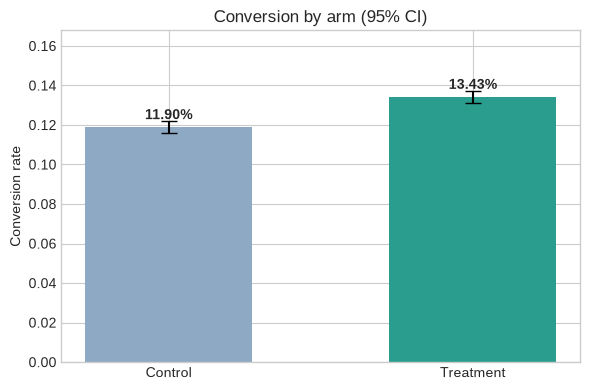

In [3]:
res = two_proportion_ztest(int(a["converted"].sum()), len(a), int(b["converted"].sum()), len(b))
chi2_p = chi_square_test(res.conv_a, res.n_a, res.conv_b, res.n_b)

print(f"Control   conversion: {res.rate_a:.4f}  ({res.conv_a:,}/{res.n_a:,})")
print(f"Treatment conversion: {res.rate_b:.4f}  ({res.conv_b:,}/{res.n_b:,})")
print(f"Difference          : {res.diff:+.4f}  (+{res.diff / res.rate_a:.1%} relative)")
print(f"95% CI              : [{res.ci_low:+.4f}, {res.ci_high:+.4f}]")
print(f"z = {res.z_stat:.2f},  p = {res.p_value:.3e}")
print(f"Chi-square cross-check p = {chi2_p:.3e}  (agrees: {np.isclose(chi2_p, res.p_value, rtol=1e-6)})")

fig, ax = plt.subplots(figsize=(6, 4))
rates = [res.rate_a, res.rate_b]
ses = [np.sqrt(res.rate_a * (1 - res.rate_a) / res.n_a), np.sqrt(res.rate_b * (1 - res.rate_b) / res.n_b)]
ax.bar(["Control", "Treatment"], rates, yerr=[1.96 * s for s in ses], capsize=6,
       color=["#8da9c4", "#2a9d8f"], width=0.55)
ax.set_ylabel("Conversion rate")
ax.set_title("Conversion by arm (95% CI)")
for i, r in enumerate(rates):
    ax.text(i, r + 0.004, f"{r:.2%}", ha="center", fontweight="bold")
ax.set_ylim(0, max(rates) * 1.25)
plt.tight_layout(); plt.show()

**Result: +1.53pp** (95% CI [+1.12, +1.94]pp), p ≈ 3.5e-13. The interval excludes both 0 and effects too small to matter — the lower bound (+1.12pp) is itself a material lift on a 11.9% baseline.

## 3. Bayesian readout — the decision quantities

Same data, Beta-Binomial model (uniform priors). Instead of a p-value we get what stakeholders actually ask: *what's the probability treatment is better, and what do we lose if we're wrong?* Expected loss of shipping B is E[max(p_A − p_B, 0)] over the posterior.

P(B > A)              = 1.0000  (no losing draws in 200,000 posterior samples)
Posterior mean diff   = +0.0153
95% credible interval = [+0.0112, +0.0194]
Expected loss, ship B = 0.000000  (conversion given up if B is secretly worse)
Expected loss, ship A = 0.015290


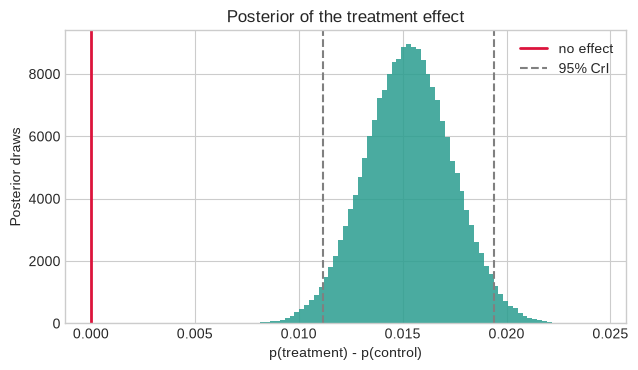

In [4]:
bayes = bayesian_analysis(res.conv_a, res.n_a, res.conv_b, res.n_b)
print(f"P(B > A)              = {bayes.prob_b_beats_a:.4f}  (no losing draws in 200,000 posterior samples)")
print(f"Posterior mean diff   = {bayes.mean_diff:+.4f}")
print(f"95% credible interval = [{bayes.ci_low:+.4f}, {bayes.ci_high:+.4f}]")
print(f"Expected loss, ship B = {bayes.expected_loss_ship_b:.6f}  (conversion given up if B is secretly worse)")
print(f"Expected loss, ship A = {bayes.expected_loss_ship_a:.6f}")

rng = np.random.default_rng(7)
da = rng.beta(*bayes.post_a, size=200_000)
db = rng.beta(*bayes.post_b, size=200_000)
diff = db - da
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(diff, bins=80, color="#2a9d8f", alpha=0.85)
ax.axvline(0, color="crimson", lw=2, label="no effect")
ax.axvline(bayes.ci_low, color="grey", ls="--"); ax.axvline(bayes.ci_high, color="grey", ls="--", label="95% CrI")
ax.set_xlabel("p(treatment) - p(control)"); ax.set_ylabel("Posterior draws")
ax.set_title("Posterior of the treatment effect"); ax.legend()
plt.tight_layout(); plt.show()

The entire posterior sits to the right of zero. P(B > A) ≈ 1.0000 and the expected loss of shipping is 0.000000 to six decimals — there is no measurable downside scenario left in the posterior.

## 4. CUPED — same answer, tighter interval

`prior_sessions` (sessions in the 30 days *before* the experiment) correlates with conversion (ρ = 0.24) and cannot be affected by treatment, so CUPED can subtract the variance it explains without biasing the estimate. θ = Cov(X, Y) / Var(X) is estimated on pooled data.

theta                       = 0.01702
corr(prior_sessions, conv)  = 0.241
Raw effect    : +0.0153  (SE 0.0021)
CUPED effect  : +0.0163  (SE 0.0020)
Outcome variance reduced by 5.8%  |  SE reduced by 3.0%


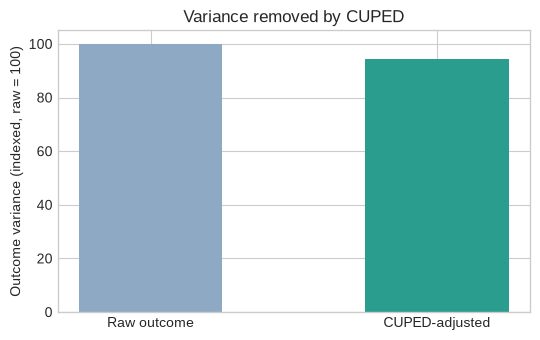

In [5]:
cuped = run_cuped(df)
print(f"theta                       = {cuped.theta:.5f}")
print(f"corr(prior_sessions, conv)  = {cuped.correlation:.3f}")
print(f"Raw effect    : {cuped.raw_effect:+.4f}  (SE {cuped.raw_se:.4f})")
print(f"CUPED effect  : {cuped.adjusted_effect:+.4f}  (SE {cuped.adjusted_se:.4f})")
print(f"Outcome variance reduced by {cuped.variance_reduction_pct:.1f}%  |  SE reduced by {cuped.se_reduction_pct:.1f}%")

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.bar(["Raw outcome", "CUPED-adjusted"], [100, 100 - cuped.variance_reduction_pct],
       color=["#8da9c4", "#2a9d8f"], width=0.5)
ax.set_ylabel("Outcome variance (indexed, raw = 100)")
ax.set_title("Variance removed by CUPED")
plt.tight_layout(); plt.show()

CUPED removes **5.8%** of the outcome variance (SE −3.0%) and moves the point estimate only slightly (+1.53pp → +1.63pp, well within noise) — exactly the signature of a valid adjustment: same estimand, less noise. That variance is worth roughly 6% fewer users for the same power, free, on every future experiment that logs this covariate.

## 5. Segments — consistent, with a multiple-comparisons warning

⚠️ **Four segment tests at α = 0.05 carry a ~19% family-wise false-positive risk.** Treat segment p-values as exploratory unless they survive correction — here we apply Bonferroni (α = 0.05/4 = 0.0125). Also note the trap in the table: absolute lifts are similar everywhere (~+1.5pp), but the *relative* lift for new users looks spectacular (+43%) purely because their baseline is low (3.5%). Ship decisions should be made on the overall effect; segments are for spotting harm or heterogeneity, not for cherry-picking a headline.

In [6]:
rows = []
for col in ("user_type", "device"):
    for val, g in df.groupby(col):
        ga, gb = g[g["arm"] == "control"], g[g["arm"] == "treatment"]
        r = two_proportion_ztest(int(ga["converted"].sum()), len(ga), int(gb["converted"].sum()), len(gb))
        rows.append({"segment": f"{col} = {val}", "n": r.n_a + r.n_b, "rate_A": r.rate_a,
                     "rate_B": r.rate_b, "diff": r.diff, "ci_low": r.ci_low,
                     "ci_high": r.ci_high, "p": r.p_value,
                     "sig_after_bonferroni": r.p_value < 0.05 / 4})
seg = pd.DataFrame(rows)
seg.style.format({"rate_A": "{:.4f}", "rate_B": "{:.4f}", "diff": "{:+.4f}",
                  "ci_low": "{:+.4f}", "ci_high": "{:+.4f}", "p": "{:.2e}"})

,segment,n,rate_A,rate_B,diff,ci_low,ci_high,p,sig_after_bonferroni
0,user_type = new,39922,0.0354,0.0508,+0.0154,+0.0114,+0.0193,4.37e-14,True
1,user_type = returning,60078,0.1737,0.1904,+0.0167,+0.0105,+0.0229,1.15e-07,True
2,device = desktop,38040,0.1243,0.1387,+0.0144,+0.0076,+0.0212,3.27e-05,True
3,device = mobile,61960,0.1157,0.1315,+0.0158,+0.0107,+0.0210,2.07e-09,True


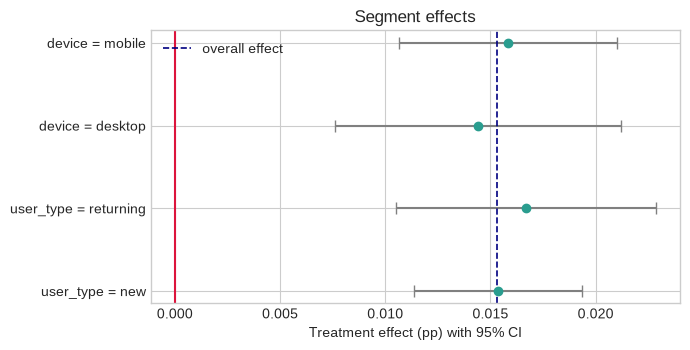

,segment,diff,p,sig_after_bonferroni
0,user_type = new,0.015362,4.367853e-14,True
1,user_type = returning,0.016693,1.147949e-07,True
2,device = desktop,0.014395,3.267638e-05,True
3,device = mobile,0.015848,2.066399e-09,True


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(seg))
ax.errorbar(seg["diff"], y, xerr=[seg["diff"] - seg["ci_low"], seg["ci_high"] - seg["diff"]],
            fmt="o", color="#2a9d8f", ecolor="grey", capsize=4)
ax.axvline(0, color="crimson", lw=1.5)
ax.axvline(res.diff, color="navy", ls="--", lw=1.2, label="overall effect")
ax.set_yticks(y); ax.set_yticklabels(seg["segment"])
ax.set_xlabel("Treatment effect (pp) with 95% CI"); ax.set_title("Segment effects")
ax.legend(); plt.tight_layout(); plt.show()
seg[["segment", "diff", "p", "sig_after_bonferroni"]]

All four segments are positive, all survive Bonferroni, and every interval overlaps the overall effect — no evidence of heterogeneity or of a harmed subgroup. The effect is broad-based, not carried by one segment.

## 6. Simulation audit — does the test keep its promises?

This is the part you can only do with known ground truth:

- **Type-I study:** 1,000 simulated experiments where treatment does *nothing*. At α = 0.05 the z-test should cry wolf ~5% of the time.
- **Power study:** 1,000 simulated experiments at the true +1.5pp design effect and this sample size. Note the design context first: 50,000 users/arm can detect **+0.58pp** at 80% power — the experiment was heavily overpowered for a +1.5pp effect (which needs only ~7,800/arm). Overpowering isn't free: it tempts early peeking and burns traffic that could run other tests.

In [8]:
print(f"Sample size for 80% power at +1.5pp, 12% baseline: {sample_size_per_arm(0.12, 0.015):,} users/arm")
print(f"MDE at the actual 50,000 users/arm: {mde_for_sample_size(0.12, 50_000):+.4f}")

t1 = type_i_error_study()
pw = power_study()
print(f"\nType-I study : {t1.false_positives}/{t1.n_sims} false positives -> empirical FPR {t1.empirical_fpr:.3f} "
      f"(nominal 0.05, MC SE {t1.mc_se:.3f})")
print(f"Power study  : {pw.rejections}/{pw.n_sims} rejections at true lift +1.5pp -> empirical power {pw.empirical_power:.3f}")

Sample size for 80% power at +1.5pp, 12% baseline: 7,756 users/arm
MDE at the actual 50,000 users/arm: +0.0058

Type-I study : 54/1000 false positives -> empirical FPR 0.054 (nominal 0.05, MC SE 0.007)
Power study  : 1000/1000 rejections at true lift +1.5pp -> empirical power 1.000


Empirical false-positive rate **0.054** vs. nominal 0.05 — within Monte Carlo error (SE 0.007); the test is calibrated. Empirical power at the design effect is **1.000** (1,000/1,000), consistent with the MDE math: at this sample size a true +1.5pp effect is essentially never missed. Both asymptotics check out against brute force.

## 7. Decision

### ✅ SHIP the new checkout flow to 100%.

**Why:**
- **Primary result is decisive:** +1.53pp [95% CI +1.12, +1.94], p ≈ 3.5e-13. The *lower* bound alone is a ~9% relative lift.
- **Bayesian check agrees, with the risk quantified:** P(B > A) ≈ 1.0000, expected loss of shipping ≈ 0.000000.
- **No data-quality flags:** no SRM; covariate and segment balance clean.
- **No harmed segment:** all four pre-declared segments positive and significant after Bonferroni; intervals consistent with the overall effect.
- **CUPED corroborates:** adjusted effect +1.63pp with a tighter SE — the result is not an artifact of covariate imbalance.

**Guardrails & caveats:**
- Guardrail metrics (refund rate, support contacts, page latency) are *not in this dataset* — in a live readout, a ship call requires them flat. Flagged here because a conversion-only readout is an incomplete one.
- **Novelty/primacy effects:** two weeks of data can't rule them out; monitor conversion weekly for the first month post-launch against the +1.1pp lower bound.
- The design was overpowered (MDE +0.58pp vs. the +1.5pp target): future tests on this surface should pre-register ~8k users/arm for this effect size, or keep 50k only if a +0.6pp decision is genuinely actionable.

**Next steps:** ramp 50% → 100% with a 1% holdback for two weeks to validate the long-term effect; add `prior_sessions` CUPED adjustment as the default for checkout experiments (≈6% variance reduction, permanently); log guardrail metrics into the experiment platform before the next test.